# Assignment 1 — Single Layer Perceptron from Scratch

**Name:** ____________________  
**Student number:** ____________________

Binary classification of **Iris Setosa (0)** and **Iris Versicolor (1)**.
The model uses only Python's standard library: `math`, lists, and loops.
Matplotlib is used only for charts. No Keras, TensorFlow, PyTorch, scikit-learn, or NumPy is used.

Run all cells in order. Keep this notebook inside `Assignment 1 SLP/` with its `data/` and `output/` folders.

In [1]:
from pathlib import Path
import csv
import math

# Supports launching Jupyter from the assignment folder or workspace root.
ROOT = Path.cwd()
if not (ROOT / "data/train.csv").exists():
    ROOT = ROOT / "Assignment 1 SLP"
if not (ROOT / "data/train.csv").exists():
    raise FileNotFoundError("Open the notebook from the assignment folder or workspace root.")
OUTPUT = ROOT / "output"
OUTPUT.mkdir(exist_ok=True)


## 1. Load the exact spreadsheet split

Four inputs: sepal length, sepal width, petal length, and petal width.
The CSV files were extracted from the course spreadsheet: **80 training samples**
(first 40 of each class) and **20 validation samples** (last 10 of each class).
Keep the original row order; do not shuffle or normalize when reproducing the spreadsheet.

In [2]:
def load_data(path):
    with path.open(newline="") as file:
        reader = csv.DictReader(file)
        features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
        rows = list(reader)
    X = [[float(row[name]) for name in features] for row in rows]
    y = [int(float(row["target"])) for row in rows]
    return X, y

X_train, y_train = load_data(ROOT / "data/train.csv")
X_valid, y_valid = load_data(ROOT / "data/validation.csv")
assert len(X_train) == 80 and len(X_valid) == 20
assert y_train.count(0) == y_train.count(1) == 40
assert y_valid.count(0) == y_valid.count(1) == 10
print("Training:", len(X_train), "Validation:", len(X_valid))
print("First training sample:", X_train[0], "Target:", y_train[0])

Training: 80 Validation: 20
First training sample: [5.1, 3.5, 1.4, 0.2] Target: 0


## 2. Implement the single neuron and gradient manually

The template uses a **sigmoid single neuron**, rather than a hard-threshold perceptron update:

$$z = b + \sum_{j=1}^{4} w_jx_j,\qquad p = \frac{1}{1+e^{-z}}$$
$$L=(p-y)^2,\qquad \delta=\frac{\partial L}{\partial z}=2(p-y)p(1-p)$$
$$b \leftarrow b-\eta\delta,\qquad w_j \leftarrow w_j-\eta\delta x_j$$

Prediction is 1 only when $p>0.5$. All gradients use the same pre-update probability.
Initial bias and all weights are 0.5; learning rate is 0.1.

In [3]:
class SingleLayerPerceptron:
    def __init__(self, n_features=4, learning_rate=0.1):
        self.weights = [0.5 for _ in range(n_features)]
        self.bias = 0.5
        self.learning_rate = learning_rate

    def probability(self, features):
        z = self.bias
        for weight, value in zip(self.weights, features):
            z += weight * value
        return 1.0 / (1.0 + math.exp(-z))

    def predict(self, features):
        return int(self.probability(features) > 0.5)

    def train_one(self, features, target):
        # Forward pass BEFORE updating weights.
        probability = self.probability(features)
        delta = 2.0 * (probability - target) * probability * (1.0 - probability)

        # Manual gradient descent: no autodiff or optimizer library.
        self.bias -= self.learning_rate * delta
        for j in range(len(self.weights)):
            self.weights[j] -= self.learning_rate * delta * features[j]
        return probability


def metrics(probabilities, targets):
    correct = 0
    squared_error = 0.0
    for probability, target in zip(probabilities, targets):
        correct += int(int(probability > 0.5) == target)
        squared_error += (probability - target) ** 2
    return correct / len(targets), squared_error / len(targets)


## 3. Train for five epochs

Training metrics average the **online, pre-update predictions** produced while processing
that epoch, as in the spreadsheet rows. Validation metrics use **frozen weights after the
last update of each epoch**. Validation data never changes the model.
Loss is **mean squared error (MSE)**.

These definitions matter: evaluating the entire training set again using the final
weights would produce a different training curve.

In [4]:
model = SingleLayerPerceptron()
history = []
checkpoints = []

for epoch in range(1, 6):
    training_probabilities = []
    for features, target in zip(X_train, y_train):
        probability = model.train_one(features, target)
        training_probabilities.append(probability)

    training_accuracy, training_loss = metrics(training_probabilities, y_train)
    validation_probabilities = [model.probability(features) for features in X_valid]
    validation_accuracy, validation_loss = metrics(validation_probabilities, y_valid)

    history.append({
        "Epoch": epoch,
        "Train accuracy": training_accuracy,
        "Validation accuracy": validation_accuracy,
        "Train MSE": training_loss,
        "Validation MSE": validation_loss,
    })
    checkpoints.append({"epoch": epoch, "bias": model.bias, "weights": model.weights.copy()})

print(f"{'Epoch':>5} {'Train acc':>12} {'Valid acc':>12} {'Train MSE':>12} {'Valid MSE':>12}")
for row in history:
    print(f"{row['Epoch']:5d} {row['Train accuracy']:12.2%} "
          f"{row['Validation accuracy']:12.2%} {row['Train MSE']:12.8f} "
          f"{row['Validation MSE']:12.8f}")


Epoch    Train acc    Valid acc    Train MSE    Valid MSE
    1       52.50%       50.00%   0.44988866   0.32895116
    2       95.00%       50.00%   0.03745191   0.24728932
    3       97.50%       50.00%   0.02437219   0.17589164
    4       97.50%       85.00%   0.01735720   0.11938137
    5       98.75%      100.00%   0.01274016   0.08158137


## 4. Verify against the completed workbook

Compare every epoch's accuracy and loss to `output/spreadsheet_metrics.csv`, exported
from the completed local workbook. This checks local workbook parity; Google Sheets
recalculation remains to be verified after importing the workbook online.

In [5]:
with (OUTPUT / "spreadsheet_metrics.csv").open(newline="") as file:
    reference = list(csv.DictReader(file))

assert len(history) == len(reference)
maximum_difference = 0.0
for actual, expected in zip(history, reference):
    for key, value in actual.items():
        difference = abs(value - float(expected[key]))
        maximum_difference = max(maximum_difference, difference)
        assert difference <= 1e-12, (actual["Epoch"], key, value, expected[key])

print(f"PASS: all five epochs match the workbook (maximum difference {maximum_difference:.3g}).")
with (OUTPUT / "notebook_metrics.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)


PASS: all five epochs match the workbook (maximum difference 1.11e-16).


## 5. Accuracy and loss charts

Matplotlib only visualizes the numbers already computed by the pure Python model.
The PNG files are saved in `output/` for use in slides 3 and 5.

Matplotlib is building the font cache; this may take a moment.


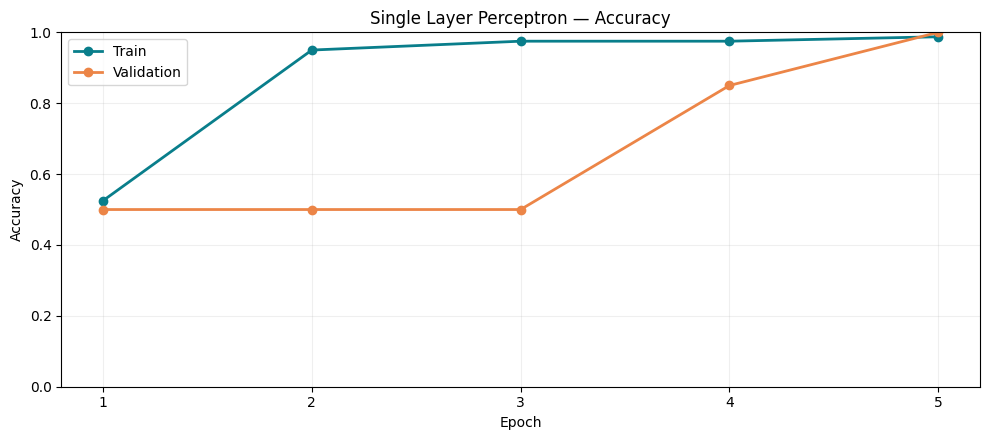

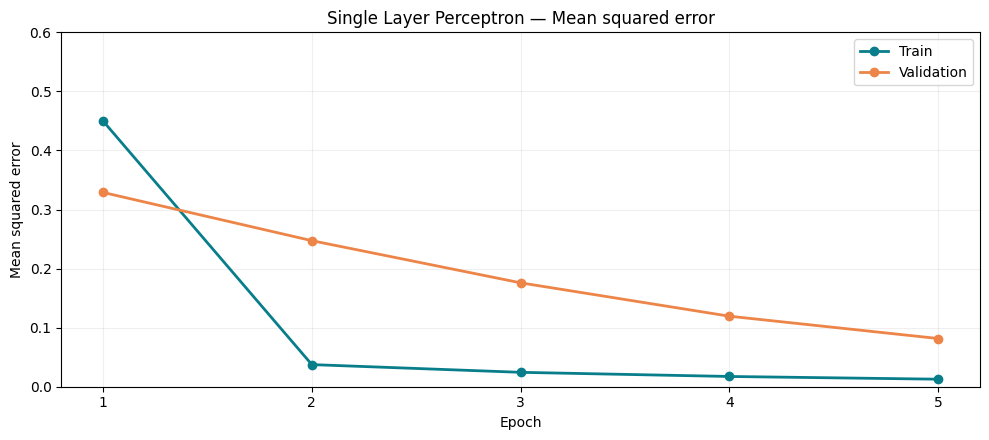

In [6]:
import matplotlib.pyplot as plt

epochs = [row["Epoch"] for row in history]
for metric, ylabel, filename in [
    ("accuracy", "Accuracy", "notebook_accuracy.png"),
    ("MSE", "Mean squared error", "notebook_loss.png"),
]:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for label, color in [("Train", "#097E8B"), ("Validation", "#EC8547")]:
        ax.plot(epochs, [row[f"{label} {metric}"] for row in history],
                marker="o", linewidth=2, color=color, label=label)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_xticks(epochs)
    ax.set_ylim(0, 1 if metric == "accuracy" else 0.6)
    ax.set_title(f"Single Layer Perceptron — {ylabel}")
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT / filename, dpi=180)
    plt.show()
    plt.close(fig)


## 6. Inspect the final model and make a prediction

In [7]:
print("Final bias:", model.bias)
print("Final weights:", model.weights)

sample = X_valid[0]
probability = model.probability(sample)
predicted = model.predict(sample)
classes = {0: "Setosa", 1: "Versicolor"}
print("Features:", sample)
print(f"P(Versicolor): {probability:.6f}")
print("Prediction:", classes[predicted])
print("Actual:", classes[y_valid[0]])


Final bias: 0.2577197481284967
Final weights: [-0.2418016548639205, -0.4169034850498341, 1.1222139008546288, 0.8240586606921434]
Features: [5.0, 3.5, 1.3, 0.3]
P(Versicolor): 0.330847
Prediction: Setosa
Actual: Setosa


## References

- [Course spreadsheet](https://docs.google.com/spreadsheets/d/1yhi8ASebpmljJ3NpYQ7NmxlWLmhGOI6W/edit?gid=1211907647): exact data split, initialization, sigmoid and update equations.
- Fisher, R. (1936). [Iris dataset, UCI Machine Learning Repository](https://doi.org/10.24432/C56C76).

The notebook performs its own training and does not call `slp.py` or any model library.